# AUM2: speaker-independent speech emotion recognition

This notebook is the narrative companion to the [AUM2 repository](https://github.com/Baraa-Melhem/AUM2).
It rebuilds the 2023 Kaggle notebook *Audio Emotional Classification* from first principles:

1. **The data**: four acted English corpora, pooled, with every speaker identified.
2. **What went wrong in 2023**: four defects you can reproduce in a few lines.
3. **The acoustic front end**: conditioning, log-mel features and on-the-fly augmentation.
4. **A leak-free protocol**: held-out test speakers and speaker-disjoint dev folds.
5. **Results**: the old method re-run honestly, a log-mel CRNN, hand-crafted features and frozen WavLM.
6. **Inference**: files of any length, with a per-window emotion timeline.

Every number here comes from `runs/` produced by `train.py`; the notebook only reads and plots them.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from aum2.config import load_config
from aum2.data.dataset import load_corpus
from aum2.data.splits import assign_folds, check_speaker_disjoint, split_summary

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
cfg = load_config("configs/base.yaml")
corpus = load_corpus(cfg.data)
manifest = corpus.manifest
print(
    f"{len(manifest):,} clips | {manifest.speaker.nunique()} speakers | "
    f"{manifest.duration.sum() / 3600:.1f} h after trimming"
)

11,311 clips | 121 speakers | 7.6 h after trimming


## 1. The data

| Corpus | Speakers | Sentences | Native rate | Licence |
|---|---|---|---|---|
| CREMA-D | 91 actors (48 m / 43 f) | 12 sentences | 16 kHz | ODbL |
| RAVDESS (speech) | 24 actors (12 m / 12 f) | 2 sentences | 48 kHz | CC BY-NC-SA 4.0 |
| TESS | 2 actresses (aged 26 and 64) | "Say the word …" × 200 | 24.4 kHz | CC BY-NC 4.0 |
| SAVEE | 4 male speakers | 15 TIMIT sentences | 44.1 kHz (mirror: 16 kHz) | research use |

The six emotions shared by all four corpora are kept (RAVDESS *calm* and every *surprise* clip are
dropped). File names are parsed with anchored regular expressions, so every clip carries its speaker.

In [2]:
counts = manifest.groupby(["corpus", "emotion"]).size().unstack(fill_value=0)
counts["clips"] = counts.sum(axis=1)
counts["speakers"] = manifest.groupby("corpus").speaker.nunique()
counts.loc["total"] = counts.sum()
counts["hours"] = (manifest.groupby("corpus").duration.sum() / 3600).reindex(counts.index)
counts.loc["total", "hours"] = manifest.duration.sum() / 3600
counts.round({"hours": 2})

emotion,angry,disgust,fear,happy,neutral,sad,clips,speakers,hours
corpus,,,,,,,,,
cremad,1270,1270,1270,1270,1086,1270,7436,91,5.13
ravdess,192,192,192,191,96,192,1055,24,0.63
savee,60,60,60,60,120,60,420,4,0.44
tess,400,400,400,400,400,400,2400,2,1.37
total,1922,1922,1922,1921,1702,1922,11311,121,7.58


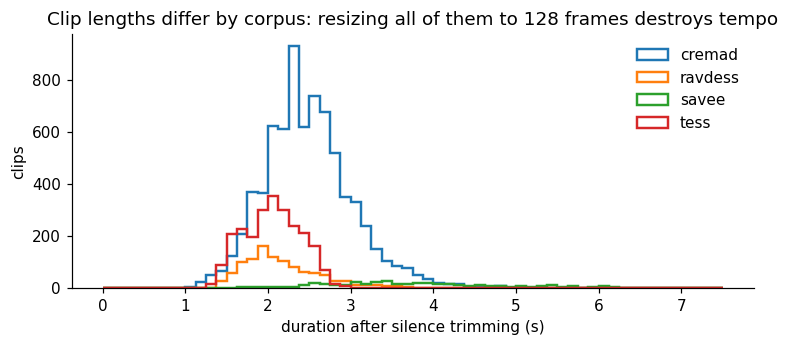

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
for corpus_name, group in manifest.groupby("corpus"):
    ax.hist(group.duration, bins=60, range=(0, 7.5), histtype="step", lw=1.6, label=corpus_name)
ax.set(
    xlabel="duration after silence trimming (s)",
    ylabel="clips",
    title="Clip lengths differ by corpus: resizing all of them to 128 frames destroys tempo",
)
ax.legend(frameon=False)
plt.show()

## 2. What went wrong in 2023

The full audit is in [`AUDIT.md`](../AUDIT.md). Four of its findings can be shown directly.

**(a) Every SAVEE clip was labelled *angry*.** The notebook tested `"a" in filename`, where
`filename` was the full Kaggle path:

In [4]:
path = "/kaggle/input/speech-emotion-recognition-en/Savee/DC_n01.wav"  # a *neutral* clip
print('"a" in path ->', "a" in path, " (matched by the 'a' in 'kaggle')")

from aum2.data.corpora import parse_savee

print("AUM2 parser   ->", parse_savee(Path(path)).emotion)

"a" in path -> True  (matched by the 'a' in 'kaggle')
AUM2 parser   -> neutral


**(b) The test set was inside the training set.** The first input dataset (`uldisvalainis/audio-emotions`)
is, per its own card, *all* of CREMA-D, TESS, RAVDESS and SAVEE. The "test" cell then scored 200 TESS
clips per emotion, which were among the training clips, and CREMA-D and SAVEE were appended a second
time on top. The 95.5–100 % per-emotion "accuracies" are training accuracies.

**(c) Every clip was squeezed to 128 frames.** With `librosa.load(sr=None)` the hop of 512 samples is
32 ms at 16 kHz but 10.7 ms at 48 kHz, and `tf.image.resize` then stretches everything to 128 columns.
Speaking rate disappears, and the corpus becomes identifiable from the image alone:

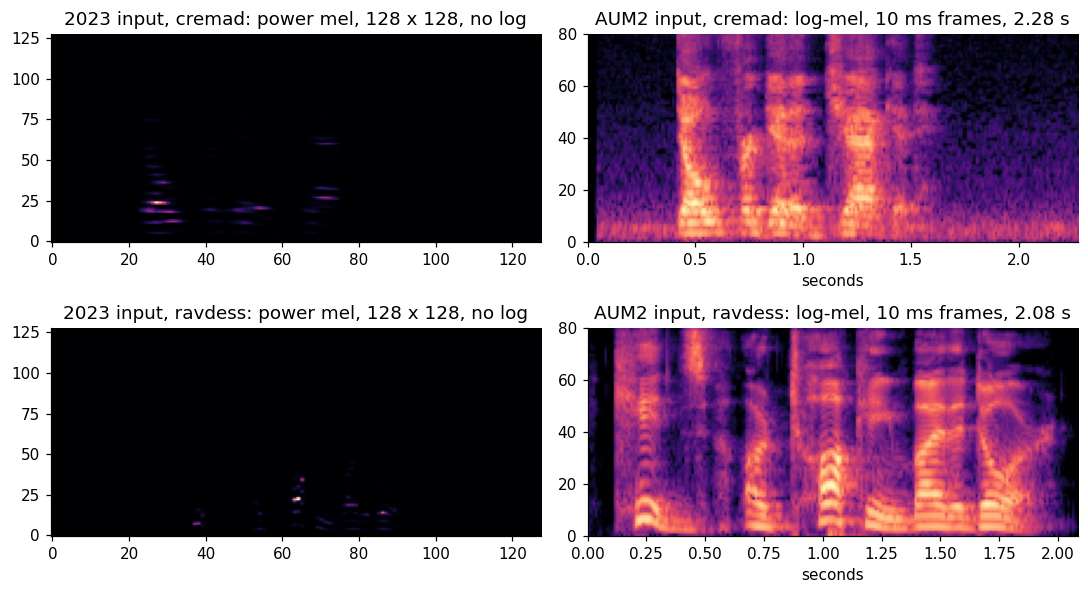

In [5]:
import librosa

from aum2.models.legacy import legacy_features

examples = {
    c: manifest[(manifest.corpus == c) & (manifest.emotion == "angry")].iloc[0]
    for c in ("cremad", "ravdess")
}
fig, axes = plt.subplots(2, 2, figsize=(10, 5.5))
for row, (c, item) in enumerate(examples.items()):
    image = legacy_features(Path(cfg.data.raw_dir) / item.path, cfg.model.legacy)
    axes[row, 0].imshow(image, origin="lower", aspect="auto", cmap="magma")
    axes[row, 0].set_title(f"2023 input, {c}: power mel, 128 x 128, no log")
    wave = corpus.waveform(int(item.name))
    mel = librosa.power_to_db(
        librosa.feature.melspectrogram(y=wave, sr=16000, n_fft=400, hop_length=160, n_mels=80)
    )
    axes[row, 1].imshow(
        mel, origin="lower", aspect="auto", cmap="magma", extent=[0, len(wave) / 16000, 0, 80]
    )
    axes[row, 1].set_title(f"AUM2 input, {c}: log-mel, 10 ms frames, {len(wave) / 16000:.2f} s")
    axes[row, 1].set_xlabel("seconds")
plt.tight_layout()
plt.show()

Without log compression the 2023 input is almost black: a handful of low-frequency bins hold nearly all
the energy, and the 10⁸ dynamic range swamps the first convolution.

**(d) The source corpora themselves contain label conflicts.** Hashing the conditioned audio finds
three CREMA-D pairs that are byte-identical files carrying *different* emotions, and one duplicated
RAVDESS take. AUM2 drops conflicting pairs, since the true label is unknowable, and keeps one copy of
an exact repeat:

In [6]:
conflicts = [
    ("1006_TIE_HAP_XX", "1006_TIE_NEU_XX"),
    ("1013_WSI_DIS_XX", "1013_WSI_SAD_XX"),
    ("1017_IWW_ANG_XX", "1017_IWW_FEA_XX"),
]
for a, b in conflicts:
    same = (
        Path(cfg.data.raw_dir, "cremad/AudioWAV", a + ".wav").read_bytes()
        == Path(cfg.data.raw_dir, "cremad/AudioWAV", b + ".wav").read_bytes()
    )
    print(f"{a} == {b}: {same}   in AUM2 corpus: {('cremad_' + a) in set(manifest.utt_id)}")

1006_TIE_HAP_XX == 1006_TIE_NEU_XX: True   in AUM2 corpus: False
1013_WSI_DIS_XX == 1013_WSI_SAD_XX: True   in AUM2 corpus: False
1017_IWW_ANG_XX == 1017_IWW_FEA_XX: True   in AUM2 corpus: False


## 3. The acoustic front end

Every clip, in training and at inference (`aum2.data.audio.condition`), is:

1. down-mixed to mono and resampled to **16 kHz** with soxr;
2. **trimmed** of edge silence quieter than the loudest 25 ms frame minus 35 dB, keeping a 100 ms margin;
3. **loudness-normalised** to −25 dBFS RMS, with a peak guard.

Models then see **80-band log-mel energies** (25 ms Hann windows, 10 ms hop), standardised per band
with statistics fitted **on the training folds only**. They are stored inside each checkpoint, so
inference cannot use the wrong ones.

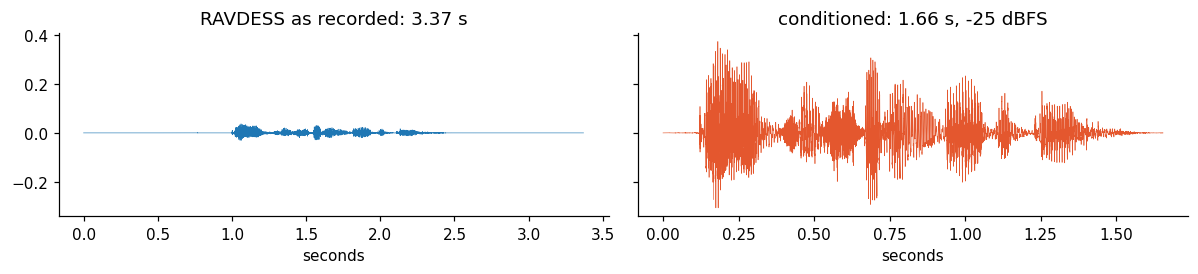

In [7]:
from aum2.data.audio import load_audio

item = manifest[(manifest.corpus == "ravdess") & (manifest.emotion == "sad")].iloc[3]
raw = load_audio(Path(cfg.data.raw_dir) / item.path, 16000)
conditioned = corpus.waveform(int(item.name))
fig, axes = plt.subplots(1, 2, figsize=(11, 2.6), sharey=True)
axes[0].plot(np.arange(len(raw)) / 16000, raw, lw=0.4)
axes[0].set_title(f"RAVDESS as recorded: {len(raw) / 16000:.2f} s")
axes[1].plot(np.arange(len(conditioned)) / 16000, conditioned, lw=0.4, color="#e4572e")
axes[1].set_title(f"conditioned: {len(conditioned) / 16000:.2f} s, -25 dBFS")
for ax in axes:
    ax.set_xlabel("seconds")
plt.tight_layout()
plt.show()

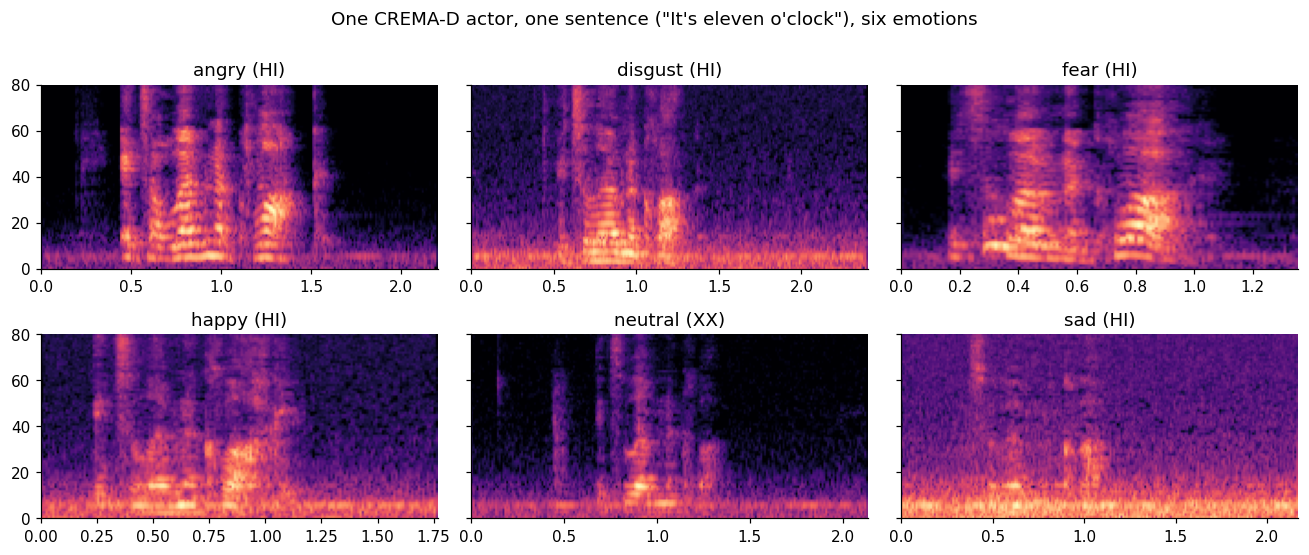

In [8]:
actor = "cremad_1015"
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharey=True)
for ax, emotion in zip(axes.flat, cfg.data.classes, strict=True):
    row = manifest[
        (manifest.speaker == actor) & (manifest.emotion == emotion) & (manifest.text_id == "IEO")
    ].iloc[0]
    wave = corpus.waveform(int(row.name))
    mel = librosa.power_to_db(
        librosa.feature.melspectrogram(y=wave, sr=16000, n_fft=400, hop_length=160, n_mels=80),
        ref=np.max,
    )
    ax.imshow(
        mel,
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=-70,
        extent=[0, len(wave) / 16000, 0, 80],
    )
    ax.set_title(f"{emotion} ({row.intensity})")
fig.suptitle("One CREMA-D actor, one sentence (\"It's eleven o'clock\"), six emotions", y=1.0)
plt.tight_layout()
plt.show()

The classical baseline summarises a clip with **1 024 functionals** (mean, std, min, p10, median, p90, max)
of 40 MFCCs with Δ and ΔΔ, chroma, spectral contrast, centroid, bandwidth, roll-off, flatness, ZCR,
RMS energy and voiced-frame F0 (`aum2.features.handcrafted`):

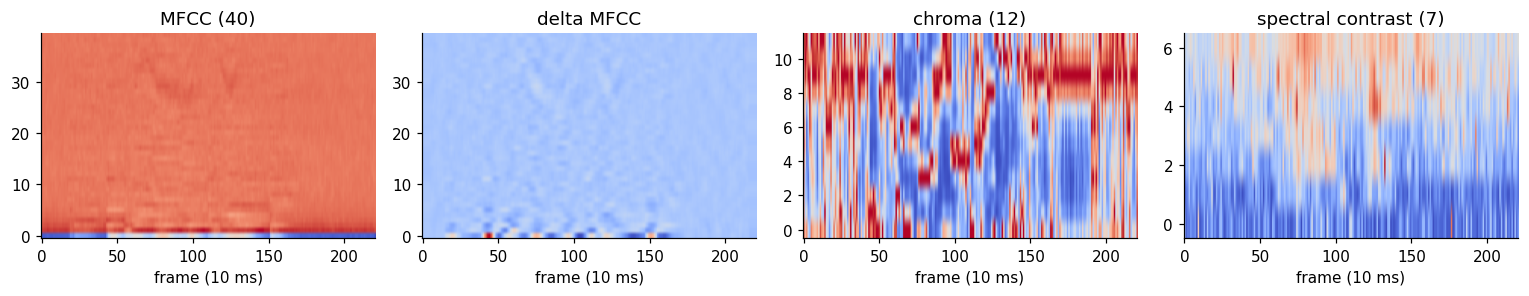

In [9]:
row = manifest[
    (manifest.speaker == actor) & (manifest.emotion == "angry") & (manifest.text_id == "IEO")
].iloc[0]
wave = corpus.waveform(int(row.name))
mfcc = librosa.feature.mfcc(y=wave, sr=16000, n_mfcc=40, n_fft=512, hop_length=160)
panels = {
    "MFCC (40)": mfcc,
    "delta MFCC": librosa.feature.delta(mfcc),
    "chroma (12)": librosa.feature.chroma_stft(y=wave, sr=16000, n_fft=512, hop_length=160),
    "spectral contrast (7)": librosa.feature.spectral_contrast(
        y=wave, sr=16000, n_fft=512, hop_length=160, fmin=100.0
    ),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for ax, (title, values) in zip(axes, panels.items(), strict=True):
    ax.imshow(values, origin="lower", aspect="auto", cmap="coolwarm")
    ax.set_title(title)
    ax.set_xlabel("frame (10 ms)")
plt.tight_layout()
plt.show()

**Augmentation runs on the GPU, on training batches only.** No augmented copy is ever stored, so no
copy can leak across a split (the 2023 notebook duplicated clips *before* splitting). Each batch draws
a random gain, coloured noise at 10–35 dB SNR, a tempo change (×0.85–1.15) and a vocal-tract-length
warp (×0.9–1.1) to simulate unseen speakers, then SpecAugment frequency and time masks:

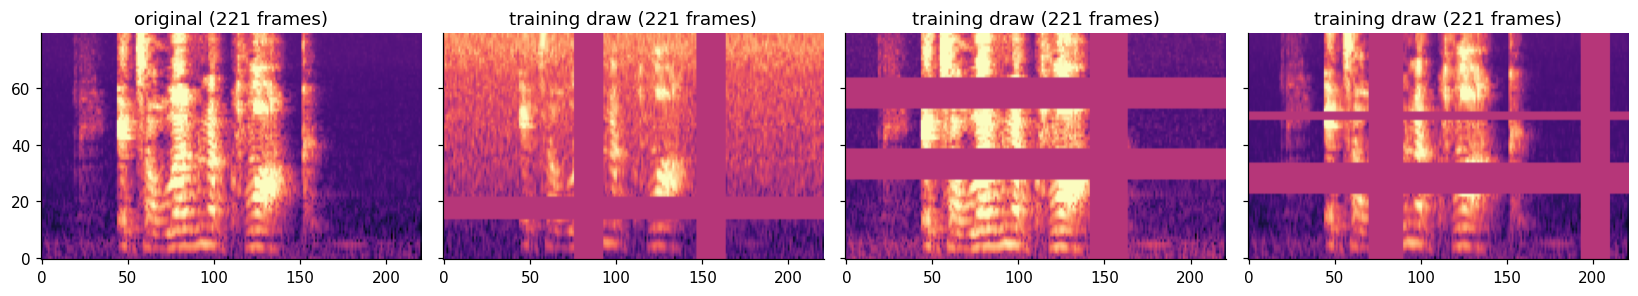

In [10]:
from aum2.features.augment import SpecAugment, WaveAugment
from aum2.features.frontend import LogMelFrontend

torch.manual_seed(3)
crnn_cfg = load_config("configs/crnn.yaml")
frontend = LogMelFrontend(crnn_cfg.frontend, 16000)
# Use the normalisation statistics a trained CRNN fold learned, so 0 = the training mean.
from safetensors.torch import load_file

state = load_file("runs/crnn/fold0/model.safetensors")
frontend.set_normalization(state["frontend.mean"], state["frontend.std"])
wave_t = torch.from_numpy(wave)[None]
lengths = torch.tensor([len(wave)])
feats, frames = frontend(wave_t, lengths)
wave_aug, spec_aug = WaveAugment(crnn_cfg.augment).train(), SpecAugment(crnn_cfg.augment).train()
fig, axes = plt.subplots(1, 4, figsize=(15, 2.8), sharey=True)
axes[0].imshow(feats[0], origin="lower", aspect="auto", cmap="magma", vmin=-2.5, vmax=2.5)
axes[0].set_title(f"original ({int(frames[0])} frames)")
for ax in axes[1:]:
    aug_feats, aug_frames = spec_aug(*frontend(wave_aug(wave_t, lengths), lengths))
    ax.imshow(aug_feats[0], origin="lower", aspect="auto", cmap="magma", vmin=-2.5, vmax=2.5)
    ax.set_title(f"training draw ({int(aug_frames[0])} frames)")
plt.tight_layout()
plt.show()

## 4. A leak-free protocol

* **Test:** 20 % of the speakers of *each* corpus, drawn per gender (18 CREMA-D actors, 5 RAVDESS actors,
  one SAVEE speaker and one TESS actress). They are never seen during training or model selection.
* **Dev:** the other speakers, in 5 speaker-disjoint folds (`StratifiedGroupKFold`). Hyper-parameters
  are chosen on dev out-of-fold UAR only (`select.py`). The reported test score is the 5-fold-model ensemble.

In [11]:
folds = assign_folds(manifest, cfg.split)
check_speaker_disjoint(manifest, folds)  # raises if any speaker appears in two partitions
split_summary(manifest, folds).unstack(fill_value=0)

clips                                   speakers                \
partition fold 0 fold 1 fold 2 fold 3 fold 4  test   fold 0 fold 1 fold 2   
corpus                                                                      
cremad      1222   1223   1147   1226   1148  1470       15     15     14   
ravdess      132    176    176    176    176   219        3      4      4   
savee          0    105    105    105      0   105        0      1      1   
tess        1200      0      0      0      0  1200        1      0      0   

                              
partition fold 3 fold 4 test  
corpus                        
cremad        15     14   18  
ravdess        4      4    5  
savee          1      0    1  
tess           0      0    1

## 5. Results

**UAR** (unweighted average recall, the mean of per-emotion recalls) is the headline metric; WAR is
plain accuracy. Test intervals are 95 % **speaker-level** bootstrap intervals: whole speakers are
resampled, because clips of one speaker are not independent.

In [12]:
RUNS = {
    "ensemble": "WavLM + HuBERT ensemble (selected)",
    "wavlm": "WavLM-Large head",
    "hubert": "HuBERT-Large head",
    "crnn": "Log-mel CRNN",
    "handcrafted": "Functionals + LightGBM",
    "legacy": "2023 method (re-run)",
}
rows = []
for name, label in RUNS.items():
    m = json.loads(Path(f"runs/{name}/metrics.json").read_text())
    t = m["test"]
    rows.append(
        {
            "model": label,
            "dev OOF UAR": m["dev"]["uar"],
            "test UAR": t["uar"],
            "95% CI": f"[{t['ci95']['uar'][0]:.3f}, {t['ci95']['uar'][1]:.3f}]",
            "test WAR": t["war"],
            "test macro-F1": t["macro_f1"],
            **{c: t["per_corpus"][c]["uar"] for c in ("cremad", "ravdess", "tess", "savee")},
        }
    )
results = pd.DataFrame(rows).set_index("model")
results

,dev OOF UAR,test UAR,95% CI,test WAR,test macro-F1,cremad,ravdess,tess,savee
model,,,,,,,,,
WavLM + HuBERT ensemble (selected),0.792,0.798,"[0.767, 0.834]",0.796,0.794,0.799,0.832,0.796,0.633
WavLM-Large head,0.770,0.805,"[0.767, 0.832]",0.804,0.801,0.796,0.849,0.815,0.644
HuBERT-Large head,0.774,0.758,"[0.728, 0.818]",0.757,0.756,0.783,0.832,0.721,0.600
Log-mel CRNN,0.656,0.729,"[0.691, 0.761]",0.727,0.725,0.726,0.786,0.737,0.467
Functionals + LightGBM,0.535,0.609,"[0.546, 0.638]",0.609,0.609,0.598,0.522,0.652,0.350
2023 method (re-run),0.353,0.402,"[0.363, 0.424]",0.400,0.406,0.407,0.343,0.417,0.194


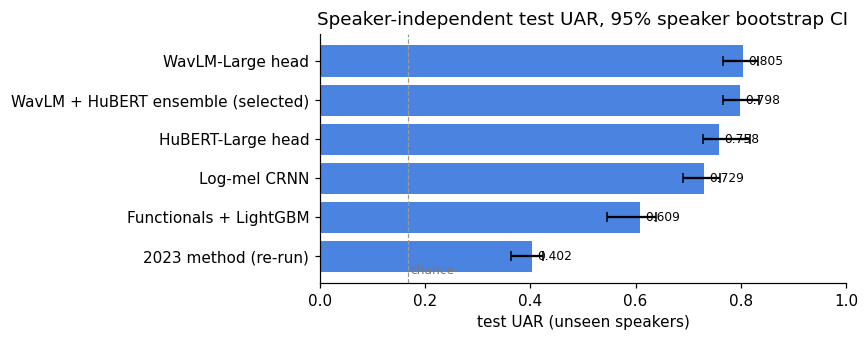

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
order = results.sort_values("test UAR")
lows = [float(ci.strip("[]").split(",")[0]) for ci in order["95% CI"]]
highs = [float(ci.strip("[]").split(",")[1]) for ci in order["95% CI"]]
ax.barh(
    order.index,
    order["test UAR"],
    color="#2a6fdb",
    alpha=0.85,
    xerr=[order["test UAR"] - lows, np.array(highs) - order["test UAR"]],
    capsize=3,
)
ax.axvline(1 / 6, color="#999999", ls="--", lw=0.8)
ax.text(1 / 6 + 0.005, -0.45, "chance", color="#777777", fontsize=8)
for y, v in enumerate(order["test UAR"]):
    ax.text(v + 0.01, y, f"{v:.3f}", va="center", fontsize=8)
ax.set(
    xlim=(0, 1),
    xlabel="test UAR (unseen speakers)",
    title="Speaker-independent test UAR, 95% speaker bootstrap CI",
)
plt.tight_layout()
plt.show()

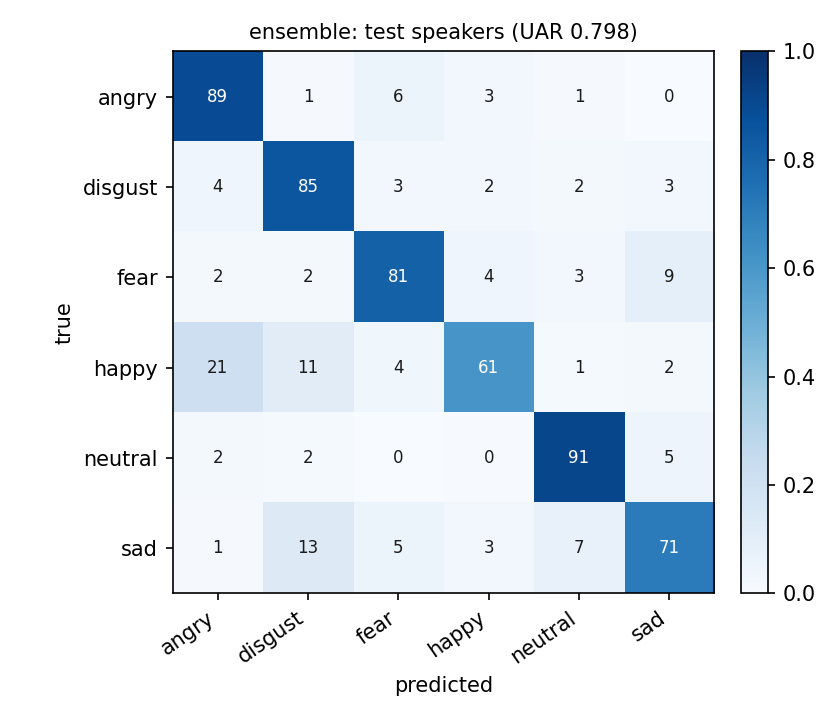

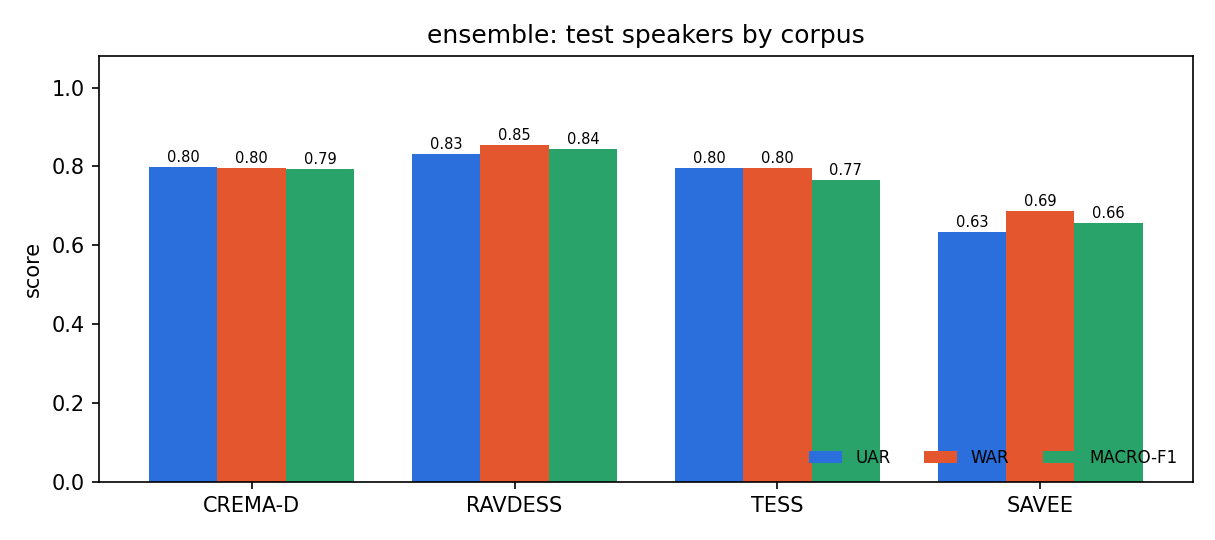

In [14]:
from IPython.display import Image, display

BEST = "ensemble"
for figure in ("confusion_test.png", "per_corpus_test.png"):
    display(Image(filename=f"runs/{BEST}/figures/{figure}", width=560))

Most of the remaining errors are **happy → disgust** on the held-out TESS actress (OAF, aged 64), whose
"happy" sits closer to the other speakers' "disgust". CREMA-D happy recall is 0.87. One TESS speaker in
training cannot cover the other's voice, which is a reminder of how much SER depends on speaker variety.

WavLM-Large's learned layer weights put most mass on the **middle layers (6–14)**: paralinguistic
information peaks there, while the top layers specialise in phonetic content.

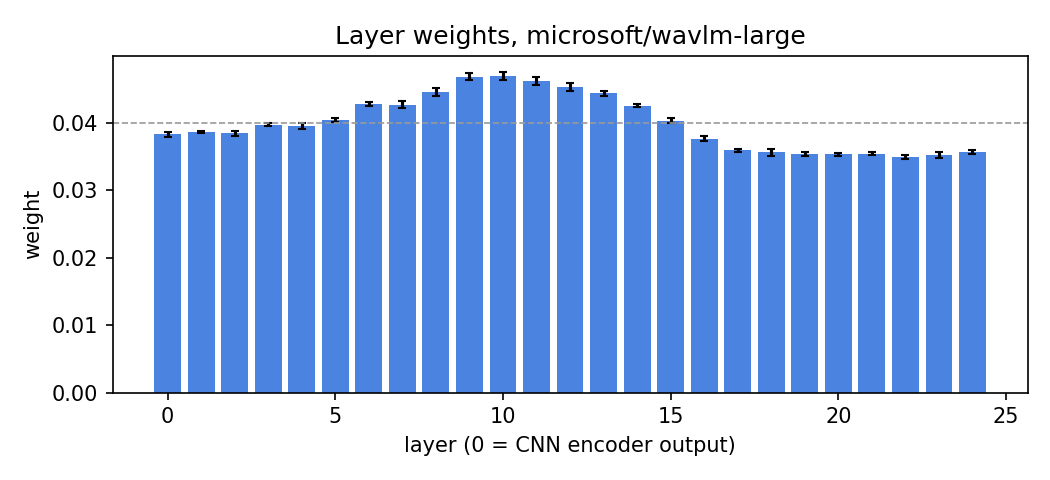

In [15]:
display(Image(filename="runs/wavlm/figures/layer_weights.png", width=640))

### How much did the 2023 protocol inflate the numbers?

The same models were re-run under the 2023 protocol: a random *utterance-level* split, so the same
speakers, sentences and recording sessions appear in training and test. The gap is the speaker leak
alone, before the duplicated and test-in-train data of the original notebook are even counted.

In [16]:
LEAK = {"WavLM-Large head": ("wavlm", "wavlm_random"), "2023 method": ("legacy", "legacy_random")}
rows = []
for label, (speaker_run, random_run) in LEAK.items():
    s = json.loads(Path(f"runs/{speaker_run}/metrics.json").read_text())["test"]
    r = json.loads(Path(f"runs/{random_run}/metrics.json").read_text())["test"]
    rows.append(
        {
            "model": label,
            "random split (2023 protocol)": r["uar"],
            "speaker-independent": s["uar"],
            "inflation (points)": 100 * (r["uar"] - s["uar"]),
        }
    )
pd.DataFrame(rows).set_index("model")

,random split (2023 protocol),speaker-independent,inflation (points)
model,,,
WavLM-Large head,0.877,0.805,7.190
2023 method,0.534,0.402,13.173


## 6. Inference

`EmotionRecognizer` loads a run's fold models and conditions audio exactly as in training. Recordings
longer than 6 s are analysed in 3 s windows with a 1.5 s hop, and silent windows are skipped. The 2023
script instead squeezed 20 s of microphone audio into a single 128-frame image.

The examples below are not cherry-picked: the clips are fixed by index and the speaker is the first
CREMA-D test speaker, so the misses stay in.

In [17]:
from aum2.inference import EmotionRecognizer

BEST_SINGLE = "wavlm"
recognizer = EmotionRecognizer(f"runs/{BEST_SINGLE}", device="cpu")  # "cuda" if available
test_rows = manifest[folds == -1]
for emotion in ("angry", "sad", "happy"):
    item = test_rows[(test_rows.corpus == "cremad") & (test_rows.emotion == emotion)].iloc[7]
    prediction = recognizer.predict_file(Path(cfg.data.raw_dir) / item.path)
    guess = f"{prediction.label:<8} ({prediction.confidence:.0%})"
    print(f"{item.utt_id}  true={emotion:<8} predicted={guess}")

cremad_1001_IWL_ANG_XX  true=angry    predicted=angry    (91%)


cremad_1001_IWL_SAD_XX  true=sad      predicted=disgust  (25%)


cremad_1001_IWL_HAP_XX  true=happy    predicted=happy    (72%)


angry (27.3%) over 17.2 s
  angry     27.3% ########
  happy     21.5% ######
  neutral   21.1% ######
  fear      18.7% ######
  disgust    5.9% ##
  sad        5.4% ##


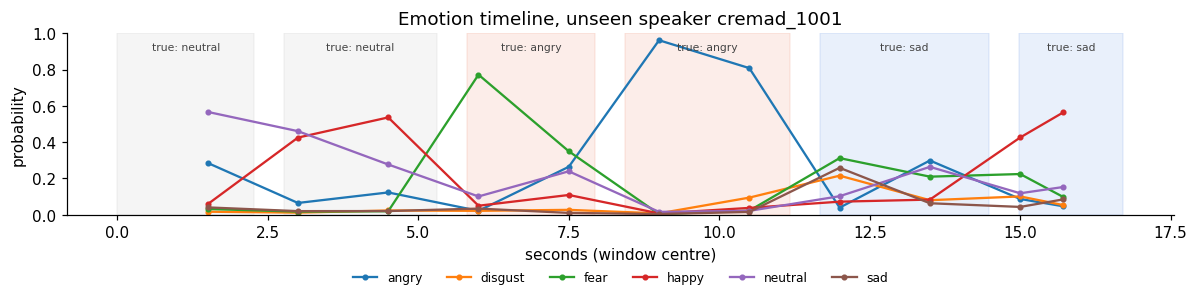

In [18]:
# A 'conversation' by one unseen speaker: neutral -> angry -> sad, stitched with pauses.
speaker = test_rows[test_rows.corpus == "cremad"].speaker.iloc[0]
pieces, truth, cursor = [], [], 0.0
for emotion in ("neutral", "neutral", "angry", "angry", "sad", "sad"):
    item = test_rows[(test_rows.speaker == speaker) & (test_rows.emotion == emotion)].sample(
        1, random_state=len(pieces)
    )
    clip = load_audio(Path(cfg.data.raw_dir) / item.path.iloc[0], 16000)
    pieces += [clip, np.zeros(8000, np.float32)]
    truth.append((cursor, cursor + len(clip) / 16000, emotion))
    cursor += len(clip) / 16000 + 0.5
recording = np.concatenate(pieces)
result = recognizer.predict_waveform(recording, 16000)
print(result)

fig, ax = plt.subplots(figsize=(11, 3.0))
shade = {"neutral": "#9e9e9e", "angry": "#e4572e", "sad": "#2a6fdb"}
for start, end, emotion in truth:
    ax.axvspan(start, end, color=shade[emotion], alpha=0.10)
    ax.text(
        (start + end) / 2,
        0.95,
        f"true: {emotion}",
        ha="center",
        va="top",
        fontsize=7,
        color="#444444",
    )
mids = [(s.start + s.end) / 2 for s in result.segments]
for emotion in recognizer.classes:
    ax.plot(
        mids, [s.probabilities[emotion] for s in result.segments], marker="o", ms=3, label=emotion
    )
ax.set(xlabel="seconds (window centre)", ylabel="probability", ylim=(0, 1))
ax.set_title(f"Emotion timeline, unseen speaker {speaker}")
ax.legend(ncol=6, frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()

For this speaker the angry sentences are caught cleanly, the neutral ones drift towards *happy*, and
the sad ones are missed. Per-speaker accuracy varies widely around the 0.80 average, which is why
the test intervals above are computed over speakers rather than clips.

## Take-aways

* The 2023 results measured memorisation. Re-run on unseen speakers, the original method scores
  **0.402** UAR; under its own random split it reaches 0.534, and the best model
  here gains 7 points from the same leak.
* Frozen self-supervised backbones with a small layer-weighted head beat every model trained from
  scratch, at a fraction of the training cost: WavLM-Large scores **0.805** test UAR, and the
  dev-selected WavLM + HuBERT ensemble scores **0.798**, a statistically indistinguishable result.
* The remaining errors are speaker effects (the older TESS speaker's *happy*, the male voices) and
  the classic fear/sad and happy/disgust pairs. More speakers, not more epochs, would move the needle.

*Licensing:* the code is GPL-2.0. Trained weights inherit the **non-commercial** terms of RAVDESS and TESS.